In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

DATA_DIR = Path("../data/processed")
REPORTS_DIR = Path("../reports")

DATASET_PATH = DATA_DIR / "intersection_day_2018_features.csv"
PROTOCOL_PATH = REPORTS_DIR / "validation_w13" / "validation_protocol.json"

In [2]:
df = pd.read_csv(
    DATASET_PATH,
    parse_dates=["prediction_date", "target_date"]
)

df = df.sort_values(
    ["prediction_date", "intersection_id"]
).reset_index(drop=True)

with PROTOCOL_PATH.open(encoding="utf-8") as file:
    validation_protocol = json.load(file)

print(f"Observations: {len(df):,}")
print(f"Intersections: {df['intersection_id'].nunique():,}")
print(f"Positive targets: {df['target'].sum():,}")
print(f"Target prevalence: {df['target'].mean():.6%}")

print("\nDataset columns:")
print(df.columns.tolist())

Observations: 823,217
Intersections: 2,258
Positive targets: 119
Target prevalence: 0.014455%

Dataset columns:
['intersection_id', 'prediction_date', 'target_date', 'historical_ksi_count', 'historical_traffic_volume', 'day_of_week', 'month', 'target', 'ksi_count_30d', 'ksi_count_365d', 'is_weekend', 'traffic_missing', 'weather_date', 'temperature_prev_day', 'precipitation_prev_day', 'weather_missing']


In [3]:
TRAIN_START = pd.Timestamp("2018-01-01")
TRAIN_END = pd.Timestamp("2018-09-29")

DEV_START = pd.Timestamp("2018-10-01")
DEV_END = pd.Timestamp("2018-12-31")

FINAL_TEST_START = pd.Timestamp("2019-01-02")
FINAL_TEST_END = pd.Timestamp("2019-12-30")

train_df = df.loc[
    df["prediction_date"].between(TRAIN_START, TRAIN_END)
].copy()

dev_df = df.loc[
    df["prediction_date"].between(DEV_START, DEV_END)
].copy()

split_summary = pd.DataFrame([
    {
        "split": name,
        "start": part["prediction_date"].min(),
        "end": part["prediction_date"].max(),
        "observations": len(part),
        "positives": part["target"].sum(),
        "prevalence": part["target"].mean()
    }
    for name, part in [
        ("train", train_df),
        ("development", dev_df)
    ]
])

display(split_summary)

,split,start,end,observations,positives,prevalence
0,train,2018-01-01,2018-09-29,613223,81,0.000132
1,development,2018-10-01,2018-12-31,207736,38,0.000183


In [4]:
from sklearn.base import clone

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

In [5]:
candidate_models = {
    "logistic_regression": LogisticRegression(
        C=0.1,
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "random_forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=10,
        max_features="sqrt",
        bootstrap=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "hist_gradient_boosting": HistGradientBoostingClassifier(
        learning_rate=0.1,
        max_iter=50,
        max_leaf_nodes=7,
        early_stopping=False,
        random_state=RANDOM_STATE
    )
}

param_grids = {
    "logistic_regression": {
        "model__C": [0.01, 0.1, 1, 10, 100]
    },

    "random_forest": {},

    "hist_gradient_boosting": {
        "model__learning_rate": [0.05, 0.1],
        "model__max_iter": [50, 100],
        "model__max_leaf_nodes": [3, 7]
    }
}

In [7]:
def make_temporal_splits(frame, n_splits=3, gap=1):
    dates = np.sort(
        frame["prediction_date"].unique()
    )

    splitter = TimeSeriesSplit(
        n_splits=n_splits,
        gap=gap
    )

    splits = []

    for train_idx, val_idx in splitter.split(dates):
        train_dates = dates[train_idx]
        val_dates = dates[val_idx]

        train_rows = np.flatnonzero(
            frame["prediction_date"].isin(train_dates).to_numpy()
        )

        val_rows = np.flatnonzero(
            frame["prediction_date"].isin(val_dates).to_numpy()
        )

        splits.append((train_rows, val_rows))

    return splits


outer_cv = make_temporal_splits(
    train_df,
    n_splits=3,
    gap=1
)

print("Candidate models:")
print(list(candidate_models))

print("\nOuter temporal folds:")

for fold, (train_idx, val_idx) in enumerate(
    outer_cv,
    start=1
):
    print(
        f"Fold {fold}: "
        f"train={len(train_idx):,}, "
        f"validation={len(val_idx):,}"
    )

print("\nAvailable columns:")
print(df.columns.tolist())

Candidate models:
['logistic_regression', 'random_forest', 'hist_gradient_boosting']

Outer temporal folds:
Fold 1: train=150,929, validation=153,204
Fold 2: train=304,133, validation=153,315
Fold 3: train=457,444, validation=153,522

Available columns:
['intersection_id', 'prediction_date', 'target_date', 'historical_ksi_count', 'historical_traffic_volume', 'day_of_week', 'month', 'target', 'ksi_count_30d', 'ksi_count_365d', 'is_weekend', 'traffic_missing', 'weather_date', 'temperature_prev_day', 'precipitation_prev_day', 'weather_missing']


In [8]:
numerical_features = [
    "historical_ksi_count",
    "historical_traffic_volume",
    "ksi_count_30d",
    "ksi_count_365d",
    "temperature_prev_day",
    "precipitation_prev_day"
]

categorical_features = [
    "day_of_week",
    "month"
]

binary_features = [
    "is_weekend",
    "traffic_missing",
    "weather_missing"
]

feature_columns = (
    numerical_features
    + categorical_features
    + binary_features
)

X_train = train_df[feature_columns]
y_train = train_df["target"]

X_dev = dev_df[feature_columns]
y_dev = dev_df["target"]

In [9]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features),
    ("binary", "passthrough", binary_features)
], remainder="drop")

In [10]:
model_pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(estimator))
    ])
    for name, estimator in candidate_models.items()
}

constant_baseline = DummyClassifier(
    strategy="prior"
)

def historical_frequency_scores(
    fit_frame,
    evaluation_frame
):
    historical_rates = (
        fit_frame
        .groupby("intersection_id")["target"]
        .mean()
    )

    global_rate = fit_frame["target"].mean()

    scores = (
        evaluation_frame["intersection_id"]
        .map(historical_rates)
        .fillna(global_rate)
        .to_numpy()
    )

    return scores

In [11]:
print(f"Training features: {X_train.shape}")
print(f"Development features: {X_dev.shape}")

print("\nModel pipelines:")

for name in model_pipelines:
    print(name)

print("\nBaselines:")
print("constant_score")
print("historical_frequency")

Training features: (613223, 11)
Development features: (207736, 11)

Model pipelines:
logistic_regression
random_forest
hist_gradient_boosting

Baselines:
constant_score
historical_frequency


In [12]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    auc,
    precision_score,
    recall_score
)

def top_k_predictions(y_scores, fraction):
    scores = np.asarray(y_scores)

    k = int(np.ceil(len(scores) * fraction))

    rng = np.random.default_rng(RANDOM_STATE)
    tie_breaker = rng.permutation(len(scores))

    ranked_indices = np.lexsort((
        tie_breaker,
        -scores
    ))

    predictions = np.zeros(len(scores), dtype=int)
    predictions[ranked_indices[:k]] = 1

    return predictions

def evaluate_scores(y_true, y_scores):
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    n_observations = len(y_true)
    n_positives = int(y_true.sum())

    has_positives = n_positives > 0
    has_both_classes = (
        0 < n_positives < n_observations
    )

    metrics = {
        "observations": n_observations,
        "positives": n_positives,
        "prevalence": y_true.mean(),
        "average_precision": np.nan,
        "pr_auc": np.nan,
        "roc_auc": np.nan
    }

    if has_positives:
        precision, recall, _ = precision_recall_curve(
            y_true,
            y_scores
        )

        metrics["average_precision"] = (
            average_precision_score(y_true, y_scores)
        )

        metrics["pr_auc"] = auc(recall, precision)

    if has_both_classes:
        metrics["roc_auc"] = roc_auc_score(
            y_true,
            y_scores
        )

    for fraction in [0.05, 0.10]:
        label = int(fraction * 100)

        predictions = top_k_predictions(
            y_scores,
            fraction
        )

        metrics[f"recall_at_{label}pct"] = (
            recall_score(y_true, predictions)
            if has_positives else np.nan
        )

        metrics[f"precision_at_{label}pct"] = (
            precision_score(
                y_true,
                predictions,
                zero_division=0
            )
        )

        metrics[f"captured_at_{label}pct"] = int(
            np.sum(y_true * predictions)
        )

        metrics[f"selected_at_{label}pct"] = int(
            predictions.sum()
        )

    return metrics

In [13]:
example_scores = np.linspace(1, 0, 20)

example_target = np.zeros(20, dtype=int)
example_target[[0, 1, 4, 10, 15]] = 1

example_metrics = evaluate_scores(
    example_target,
    example_scores
)

display(
    pd.Series(
        example_metrics,
        name="example"
    )
)

observations          20.000000
positives              5.000000
prevalence             0.250000
average_precision      0.655227
pr_auc                 0.634280
roc_auc                0.733333
recall_at_5pct         0.200000
precision_at_5pct      1.000000
captured_at_5pct       1.000000
selected_at_5pct       1.000000
recall_at_10pct        0.400000
precision_at_10pct     1.000000
captured_at_10pct      2.000000
selected_at_10pct      2.000000
Name: example, dtype: float64

In [14]:
def fit_candidate(name, fit_frame):
    X_fit = fit_frame[feature_columns]
    y_fit = fit_frame["target"]

    pipeline = clone(model_pipelines[name])
    param_grid = param_grids[name]

    if param_grid:
        inner_cv = make_temporal_splits(
            fit_frame,
            n_splits=2,
            gap=1
        )

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            scoring="average_precision",
            cv=inner_cv,
            refit=True,
            n_jobs=1,
            error_score="raise"
        )

        search.fit(X_fit, y_fit)

        return (
            search.best_estimator_,
            search.best_params_,
            search.best_score_
        )

    pipeline.fit(X_fit, y_fit)

    return pipeline, {}, np.nan

In [15]:
from time import perf_counter

outer_results = []
outer_predictions = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv,
    start=1
):
    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]

    X_fold_train = fold_train[feature_columns]
    y_fold_train = fold_train["target"]

    X_fold_val = fold_val[feature_columns]
    y_fold_val = fold_val["target"]

    print(f"\n{'=' * 50}")
    print(f"OUTER FOLD {fold}")
    print(f"Train positives: {y_fold_train.sum()}")
    print(f"Validation positives: {y_fold_val.sum()}")

    fold_scores = {}

    dummy = clone(constant_baseline)
    dummy.fit(X_fold_train, y_fold_train)

    fold_scores["constant_score"] = (
        dummy.predict_proba(X_fold_val)[:, 1]
    )

    fold_scores["historical_frequency"] = (
        historical_frequency_scores(
            fold_train,
            fold_val
        )
    )

    fit_metadata = {}

    for name in model_pipelines:
        started = perf_counter()

        fitted_model, best_params, inner_ap = (
            fit_candidate(name, fold_train)
        )

        fit_seconds = perf_counter() - started

        fold_scores[name] = (
            fitted_model.predict_proba(X_fold_val)[:, 1]
        )

        fit_metadata[name] = {
            "best_params": best_params,
            "inner_ap": inner_ap,
            "fit_seconds": fit_seconds
        }

        print(
            f"{name}: "
            f"fit completed in {fit_seconds:.2f}s"
        )

    for name, scores in fold_scores.items():
        metrics = evaluate_scores(
            y_fold_val,
            scores
        )

        metadata = fit_metadata.get(name, {})

        outer_results.append({
            "fold": fold,
            "model": name,
            **metrics,
            "best_params": metadata.get("best_params", {}),
            "inner_ap": metadata.get("inner_ap", np.nan),
            "fit_seconds": metadata.get("fit_seconds", np.nan)
        })

        prediction_frame = fold_val[
            ["intersection_id", "prediction_date", "target"]
        ].copy()

        prediction_frame["fold"] = fold
        prediction_frame["model"] = name
        prediction_frame["risk_score"] = scores

        outer_predictions.append(prediction_frame)

        print(
            f"{name}: "
            f"AP={metrics['average_precision']:.8f}, "
            f"R@5%={metrics['recall_at_5pct']:.2%}, "
            f"R@10%={metrics['recall_at_10pct']:.2%}"
        )

outer_results_df = pd.DataFrame(outer_results)

outer_predictions_df = pd.concat(
    outer_predictions,
    ignore_index=True
)


OUTER FOLD 1
Train positives: 14
Validation positives: 20
logistic_regression: fit completed in 7.92s
random_forest: fit completed in 5.63s
hist_gradient_boosting: fit completed in 23.93s
constant_score: AP=0.00013054, R@5%=0.00%, R@10%=0.00%
historical_frequency: AP=0.00013054, R@5%=0.00%, R@10%=0.00%
logistic_regression: AP=0.00015025, R@5%=5.00%, R@10%=10.00%
random_forest: AP=0.00017213, R@5%=5.00%, R@10%=10.00%
hist_gradient_boosting: AP=0.00013946, R@5%=5.00%, R@10%=5.00%

OUTER FOLD 2
Train positives: 34
Validation positives: 18
logistic_regression: fit completed in 5.07s
random_forest: fit completed in 11.29s
hist_gradient_boosting: fit completed in 46.36s
constant_score: AP=0.00011741, R@5%=11.11%, R@10%=11.11%
historical_frequency: AP=0.00020048, R@5%=22.22%, R@10%=22.22%
logistic_regression: AP=0.00039896, R@5%=27.78%, R@10%=38.89%
random_forest: AP=0.00032252, R@5%=27.78%, R@10%=38.89%
hist_gradient_boosting: AP=0.00033082, R@5%=11.11%, R@10%=44.44%

OUTER FOLD 3
Train pos

In [16]:
outer_summary = (
    outer_results_df
    .groupby("model", as_index=False)
    .agg(
        mean_ap=("average_precision", "mean"),
        std_ap=("average_precision", "std"),
        mean_pr_auc=("pr_auc", "mean"),
        mean_roc_auc=("roc_auc", "mean"),
        mean_recall_5pct=("recall_at_5pct", "mean"),
        mean_recall_10pct=("recall_at_10pct", "mean"),
        mean_precision_5pct=("precision_at_5pct", "mean"),
        mean_precision_10pct=("precision_at_10pct", "mean"),
        total_positives=("positives", "sum"),
        captured_5pct=("captured_at_5pct", "sum"),
        captured_10pct=("captured_at_10pct", "sum"),
        mean_fit_seconds=("fit_seconds", "mean")
    )
)

outer_summary["pooled_recall_5pct"] = (
    outer_summary["captured_5pct"]
    / outer_summary["total_positives"]
)

outer_summary["pooled_recall_10pct"] = (
    outer_summary["captured_10pct"]
    / outer_summary["total_positives"]
)

outer_summary = (
    outer_summary
    .sort_values("mean_ap", ascending=False)
    .reset_index(drop=True)
)

display(outer_summary.round(8))

,model,mean_ap,std_ap,mean_pr_auc,mean_roc_auc,mean_recall_5pct,mean_recall_10pct,mean_precision_5pct,mean_precision_10pct,total_positives,captured_5pct,captured_10pct,mean_fit_seconds,pooled_recall_5pct,pooled_recall_10pct
0,logistic_regression,0.000904,0.001097,0.000563,0.584665,0.143742,0.208940,0.000391,0.000283,67,9,13,6.230110,0.134328,0.194030
1,hist_gradient_boosting,0.000276,0.000119,0.000245,0.562076,0.111175,0.233780,0.000348,0.000326,67,8,15,42.938920,0.119403,0.223881
2,random_forest,0.000271,0.000085,0.000241,0.600346,0.143742,0.220434,0.000391,0.000304,67,9,14,10.680939,0.134328,0.208955
3,historical_frequency,0.000173,0.000037,0.018727,0.511196,0.074074,0.097063,0.000174,0.000130,67,4,6,NaN,0.059701,0.089552
4,constant_score,0.000146,0.000038,0.500073,0.500000,0.060026,0.060026,0.000174,0.000087,67,4,4,NaN,0.059701,0.059701


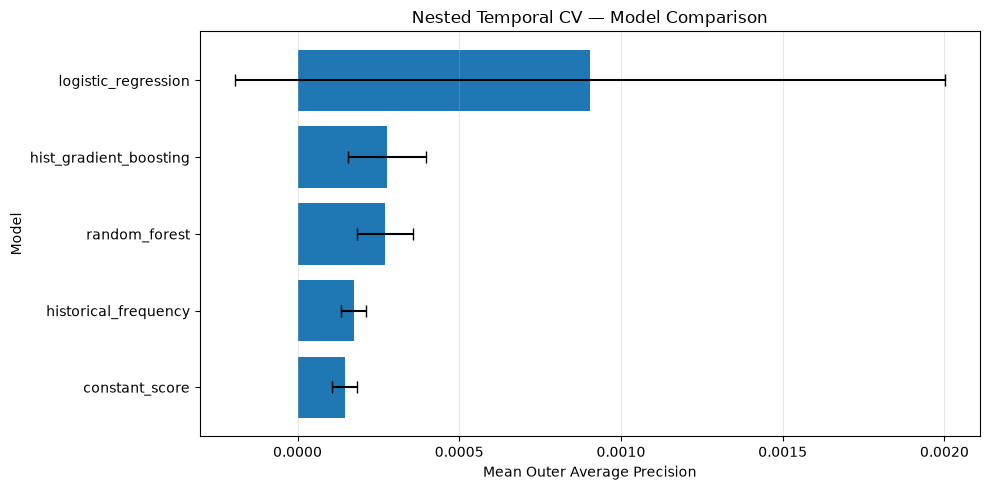

In [17]:
plot_df = outer_summary.sort_values(
    "mean_ap",
    ascending=True
)

plt.figure(figsize=(10, 5))

plt.barh(
    plot_df["model"],
    plot_df["mean_ap"],
    xerr=plot_df["std_ap"],
    capsize=4
)

plt.xlabel("Mean Outer Average Precision")
plt.ylabel("Model")
plt.title("Nested Temporal CV — Model Comparison")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
display(
    outer_results_df.pivot(
        index="model",
        columns="fold",
        values="average_precision"
    ).round(8)
)

display(
    outer_results_df.loc[
        outer_results_df["model"].isin([
            "logistic_regression",
            "hist_gradient_boosting"
        ]),
        ["model", "fold", "best_params", "inner_ap"]
    ]
)

fold,1,2,3
model,,,
constant_score,0.000131,0.000117,0.000189
hist_gradient_boosting,0.000139,0.000331,0.000359
historical_frequency,0.000131,0.000200,0.000189
logistic_regression,0.000150,0.000399,0.002162
random_forest,0.000172,0.000323,0.000317


,model,fold,best_params,inner_ap
2,logistic_regression,1,{'model__C': 0.01},0.000351
4,hist_gradient_boosting,1,"{'model__learning_rate': 0.1, 'model__max_iter...",0.000221
7,logistic_regression,2,{'model__C': 0.01},0.000262
9,hist_gradient_boosting,2,"{'model__learning_rate': 0.05, 'model__max_ite...",0.000146
12,logistic_regression,3,{'model__C': 0.1},0.000399
14,hist_gradient_boosting,3,"{'model__learning_rate': 0.05, 'model__max_ite...",0.000328


In [19]:
dev_scores = {}
dev_fitted_models = {}
dev_fit_metadata = {}

dummy = clone(constant_baseline)
dummy.fit(X_train, y_train)

dev_scores["constant_score"] = (
    dummy.predict_proba(X_dev)[:, 1]
)

dev_scores["historical_frequency"] = (
    historical_frequency_scores(
        train_df,
        dev_df
    )
)

for name in model_pipelines:
    started = perf_counter()

    fitted_model, best_params, inner_ap = (
        fit_candidate(name, train_df)
    )

    fit_seconds = perf_counter() - started

    dev_fitted_models[name] = fitted_model

    dev_scores[name] = (
        fitted_model.predict_proba(X_dev)[:, 1]
    )

    dev_fit_metadata[name] = {
        "best_params": best_params,
        "inner_ap": inner_ap,
        "fit_seconds": fit_seconds
    }

    print(
        f"{name}: "
        f"fit completed in {fit_seconds:.2f}s"
    )

    print(f"Best parameters: {best_params}")

logistic_regression: fit completed in 13.36s
Best parameters: {'model__C': 100}
random_forest: fit completed in 30.08s
Best parameters: {}
hist_gradient_boosting: fit completed in 114.89s
Best parameters: {'model__learning_rate': 0.05, 'model__max_iter': 50, 'model__max_leaf_nodes': 3}


In [20]:
dev_results = []

for name, scores in dev_scores.items():
    metrics = evaluate_scores(
        y_dev,
        scores
    )

    metadata = dev_fit_metadata.get(name, {})

    dev_results.append({
        "model": name,
        **metrics,
        "best_params": metadata.get("best_params", {}),
        "inner_ap": metadata.get("inner_ap", np.nan),
        "fit_seconds": metadata.get("fit_seconds", np.nan)
    })

dev_results_df = (
    pd.DataFrame(dev_results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

display(dev_results_df.round(8))

,model,observations,positives,prevalence,average_precision,pr_auc,roc_auc,recall_at_5pct,precision_at_5pct,captured_at_5pct,selected_at_5pct,recall_at_10pct,precision_at_10pct,captured_at_10pct,selected_at_10pct,best_params,inner_ap,fit_seconds
0,random_forest,207736,38,0.000183,0.000400,0.000369,0.692937,0.184211,0.000674,7,10387,0.263158,0.000481,10,20774,{},NaN,30.080710
1,logistic_regression,207736,38,0.000183,0.000390,0.000350,0.649370,0.105263,0.000385,4,10387,0.263158,0.000481,10,20774,{'model__C': 100},0.000882,13.360419
2,hist_gradient_boosting,207736,38,0.000183,0.000370,0.000359,0.672094,0.157895,0.000578,6,10387,0.315789,0.000578,12,20774,"{'model__learning_rate': 0.05, 'model__max_ite...",0.000247,114.892518
3,constant_score,207736,38,0.000183,0.000183,0.500091,0.500000,0.078947,0.000289,3,10387,0.157895,0.000289,6,20774,{},NaN,NaN
4,historical_frequency,207736,38,0.000183,0.000182,0.000158,0.495652,0.052632,0.000193,2,10387,0.105263,0.000193,4,20774,{},NaN,NaN


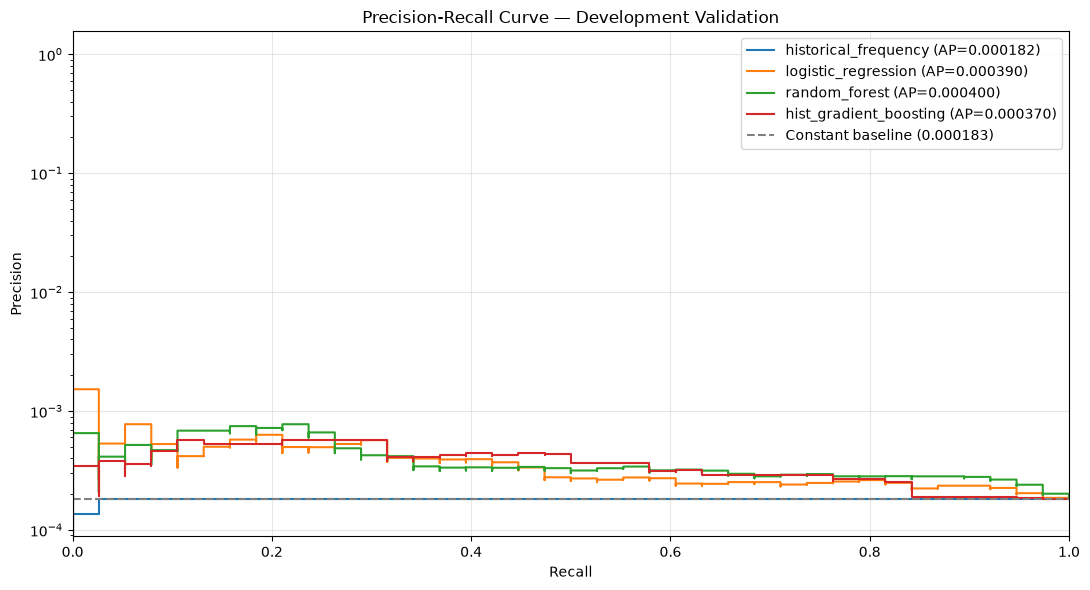

In [21]:
plt.figure(figsize=(11, 6))

for name, scores in dev_scores.items():
    if name == "constant_score":
        continue

    precision, recall, _ = precision_recall_curve(
        y_dev,
        scores
    )

    ap = average_precision_score(y_dev, scores)

    plt.step(
        recall,
        precision,
        where="post",
        label=f"{name} (AP={ap:.6f})"
    )

plt.axhline(
    y=y_dev.mean(),
    linestyle="--",
    color="gray",
    label=f"Constant baseline ({y_dev.mean():.6f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Development Validation")

plt.xlim(0, 1)
plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
dev_comparison = dev_results_df[[
    "model",
    "average_precision",
    "pr_auc",
    "roc_auc",
    "recall_at_5pct",
    "recall_at_10pct",
    "precision_at_5pct",
    "precision_at_10pct",
    "captured_at_5pct",
    "captured_at_10pct"
]].rename(
    columns={
        "average_precision": "dev_ap",
        "pr_auc": "dev_pr_auc",
        "roc_auc": "dev_roc_auc",
        "recall_at_5pct": "dev_recall_5pct",
        "recall_at_10pct": "dev_recall_10pct",
        "precision_at_5pct": "dev_precision_5pct",
        "precision_at_10pct": "dev_precision_10pct",
        "captured_at_5pct": "dev_captured_5pct",
        "captured_at_10pct": "dev_captured_10pct"
    }
)

model_comparison = outer_summary.merge(
    dev_comparison,
    on="model"
)

model_comparison["outer_ap_lift"] = (
    model_comparison["mean_ap"]
    / outer_summary.loc[
        outer_summary["model"] == "constant_score",
        "mean_ap"
    ].iloc[0]
)

model_comparison["dev_ap_lift"] = (
    model_comparison["dev_ap"]
    / y_dev.mean()
)

model_comparison = (
    model_comparison
    .sort_values("mean_ap", ascending=False)
    .reset_index(drop=True)
)

display(model_comparison[[
    "model",
    "mean_ap",
    "std_ap",
    "outer_ap_lift",
    "dev_ap",
    "dev_ap_lift",
    "pooled_recall_5pct",
    "pooled_recall_10pct",
    "dev_recall_5pct",
    "dev_recall_10pct",
    "dev_captured_5pct",
    "dev_captured_10pct"
]].round(8))

,model,mean_ap,std_ap,outer_ap_lift,dev_ap,dev_ap_lift,pooled_recall_5pct,pooled_recall_10pct,dev_recall_5pct,dev_recall_10pct,dev_captured_5pct,dev_captured_10pct
0,logistic_regression,0.000904,0.001097,6.205761,0.000390,2.130863,0.134328,0.194030,0.105263,0.263158,4,10
1,hist_gradient_boosting,0.000276,0.000119,1.898365,0.000370,2.025150,0.119403,0.223881,0.157895,0.315789,6,12
2,random_forest,0.000271,0.000085,1.857917,0.000400,2.185491,0.134328,0.208955,0.184211,0.263158,7,10
3,historical_frequency,0.000173,0.000037,1.190162,0.000182,0.993478,0.059701,0.089552,0.052632,0.105263,2,4
4,constant_score,0.000146,0.000038,1.000000,0.000183,1.000000,0.059701,0.059701,0.078947,0.157895,3,6


In [23]:
FINAL_MODEL_NAME = "logistic_regression"

FINAL_MODEL_PARAMS = (
    dev_fit_metadata[FINAL_MODEL_NAME]["best_params"].copy()
)

final_pipeline = clone(
    model_pipelines[FINAL_MODEL_NAME]
).set_params(
    **FINAL_MODEL_PARAMS
)

final_train_df = df.copy()

X_final_train = final_train_df[feature_columns]
y_final_train = final_train_df["target"]

assert (
    final_train_df["target_date"].max()
    < FINAL_TEST_START
)

print(f"Final model: {FINAL_MODEL_NAME}")
print(f"Final parameters: {FINAL_MODEL_PARAMS}")

print(f"\nTraining observations: {len(X_final_train):,}")
print(f"Training positives: {y_final_train.sum():,}")

print(
    f"Last training target date: "
    f"{final_train_df['target_date'].max().date()}"
)

Final model: logistic_regression
Final parameters: {'model__C': 100}

Training observations: 823,217
Training positives: 119
Last training target date: 2019-01-01


In [24]:
import sklearn

W14_REPORTS_DIR = REPORTS_DIR / "evaluation_w14"

W14_REPORTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

selected_outer = (
    outer_summary
    .set_index("model")
    .loc[FINAL_MODEL_NAME]
)

selected_dev = (
    dev_results_df
    .set_index("model")
    .loc[FINAL_MODEL_NAME]
)

model_selection = {
    "week": "W14",
    "selected_model": FINAL_MODEL_NAME,
    "selected_params": FINAL_MODEL_PARAMS,
    "random_state": RANDOM_STATE,
    "feature_columns": feature_columns,

    "selection": {
        "primary_metric": "mean_outer_average_precision",
        "outer_mean_ap": float(selected_outer["mean_ap"]),
        "outer_std_ap": float(selected_outer["std_ap"]),
        "development_ap": float(selected_dev["average_precision"]),
        "development_recall_5pct": float(
            selected_dev["recall_at_5pct"]
        ),
        "development_recall_10pct": float(
            selected_dev["recall_at_10pct"]
        )
    },

    "final_training": {
        "start": str(
            final_train_df["prediction_date"].min().date()
        ),
        "end": str(
            final_train_df["prediction_date"].max().date()
        ),
        "observations": len(final_train_df),
        "positives": int(y_final_train.sum())
    },

    "final_test": {
        "start": str(FINAL_TEST_START.date()),
        "end": str(FINAL_TEST_END.date()),
        "prediction_horizon_days": 1,
        "top_k_fractions": [0.05, 0.10],
        "ranking_scope": "entire_evaluation_period",
        "top_k_rounding": "ceil",
        "tie_breaker": "seeded_random_permutation",
        "reference_baselines": [
            "constant_score",
            "historical_frequency"
        ],
        "calibration_applied": False,
        "hyperparameter_tuning_allowed": False
    },

    "environment": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__
    },

    "limitations": [
        "Extremely rare positive class",
        "High variability across temporal folds",
        "Development data reused during model selection",
        "Historical data reporting latency not verified",
        "Risk scores are not validated calibrated probabilities"
    ]
}

selection_path = W14_REPORTS_DIR / "model_selection.json"

if selection_path.exists():
    with selection_path.open(encoding="utf-8") as file:
        existing_selection = json.load(file)

    if existing_selection != model_selection:
        raise ValueError(
            "Existing frozen model configuration differs."
        )
else:
    with selection_path.open("w", encoding="utf-8") as file:
        json.dump(model_selection, file, indent=4)

print(f"Model selection saved: {selection_path}")

Model selection saved: ..\reports\evaluation_w14\model_selection.json


In [25]:
RAW_DATA_DIR = Path("../data/raw")

print("Available raw data files:\n")

for path in sorted(RAW_DATA_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(RAW_DATA_DIR))

Available raw data files:

.gitkeep
en_climate_daily_ON_6158731_2017_P1D.csv
en_climate_daily_ON_6158731_2018_P1D.csv
Motor Vehicle Collisions with KSI Data - 4326.csv
tmc_summary_data.csv
traffic-signals.csv
Traffic_Collisions_Open_Data_8128730402587031536.csv


In [26]:
KSI_ARCHIVE_PATH = Path(
    "../data/interim/ksi_events.csv"
)

MATCHED_EVENTS_PATH = (
    DATA_DIR / "ksi_matched_events.csv"
)

ksi_archive = pd.read_csv(
    KSI_ARCHIVE_PATH,
    usecols=["accdate"]
)

archive_dates = pd.to_datetime(
    ksi_archive["accdate"],
    errors="coerce"
).dt.normalize()

matched_events = pd.read_csv(
    MATCHED_EVENTS_PATH,
    usecols=["event_date"],
    parse_dates=["event_date"]
)

first_target_date = (
    FINAL_TEST_START + pd.Timedelta(days=1)
)

last_target_date = (
    FINAL_TEST_END + pd.Timedelta(days=1)
)

required_months = pd.period_range(
    first_target_date,
    last_target_date,
    freq="M"
)

available_months = (
    archive_dates.dropna().dt.to_period("M").unique()
)

assert archive_dates.min() <= first_target_date
assert archive_dates.max() >= last_target_date
assert required_months.isin(available_months).all()

assert matched_events["event_date"].notna().all()

print(
    f"KSI archive coverage: "
    f"{archive_dates.min().date()} — "
    f"{archive_dates.max().date()}"
)

print(
    f"Matched events coverage: "
    f"{matched_events['event_date'].min().date()} — "
    f"{matched_events['event_date'].max().date()}"
)

print("KSI archive temporal coverage checks passed.")

KSI archive coverage: 2006-01-01 — 2026-09-15
Matched events coverage: 2006-01-04 — 2026-08-28
KSI archive temporal coverage checks passed.


In [27]:
assert FINAL_MODEL_NAME == "logistic_regression"

assert (
    final_pipeline.get_params()["model__C"]
    == FINAL_MODEL_PARAMS["model__C"]
)

assert FINAL_MODEL_PARAMS["model__C"] == 100

assert (
    final_train_df["target_date"].max()
    < FINAL_TEST_START
)

started = perf_counter()

final_pipeline.fit(
    X_final_train,
    y_final_train
)

final_fit_seconds = perf_counter() - started

print("Final model training completed.")
print(f"Model: {FINAL_MODEL_NAME}")
print(f"Parameters: {FINAL_MODEL_PARAMS}")

print(f"Training observations: {len(X_final_train):,}")
print(f"Training positives: {y_final_train.sum():,}")

print(f"Fit time: {final_fit_seconds:.2f}s")

print(
    "Solver iterations:",
    final_pipeline.named_steps["model"].n_iter_
)

Final model training completed.
Model: logistic_regression
Parameters: {'model__C': 100}
Training observations: 823,217
Training positives: 119
Fit time: 3.11s
Solver iterations: [12]


In [28]:
FINAL_TEST_PATH = (
    DATA_DIR / "intersection_day_2019_features.csv"
)

final_test_df = pd.read_csv(
    FINAL_TEST_PATH,
    parse_dates=[
        "prediction_date",
        "target_date",
        "weather_date"
    ]
)

final_test_df = (
    final_test_df
    .sort_values([
        "prediction_date",
        "intersection_id"
    ])
    .reset_index(drop=True)
)

assert final_test_df["prediction_date"].min() == FINAL_TEST_START

assert final_test_df["prediction_date"].max() == FINAL_TEST_END

assert set(final_test_df.columns) == set(final_train_df.columns)

assert not final_test_df.duplicated([
    "intersection_id",
    "prediction_date"
]).any()

X_final_test = final_test_df[feature_columns]
y_final_test = final_test_df["target"]

assert X_final_test.columns.equals(
    X_final_train.columns
)

assert y_final_test.isin([0, 1]).all()
assert y_final_test.nunique() == 2

print(f"Final test observations: {len(X_final_test):,}")
print(f"Final test positives: {y_final_test.sum():,}")
print(f"Final test prevalence: {y_final_test.mean():.6%}")

Final test observations: 819,654
Final test positives: 133
Final test prevalence: 0.016226%


In [29]:
final_scores = {}

final_dummy = clone(constant_baseline)

final_dummy.fit(
    X_final_train,
    y_final_train
)

final_scores["constant_score"] = (
    final_dummy.predict_proba(X_final_test)[:, 1]
)

final_scores["historical_frequency"] = (
    historical_frequency_scores(
        final_train_df,
        final_test_df
    )
)

started = perf_counter()

final_scores[FINAL_MODEL_NAME] = (
    final_pipeline.predict_proba(X_final_test)[:, 1]
)

final_predict_seconds = (
    perf_counter() - started
)

print("Final test predictions completed.")

for name, scores in final_scores.items():
    print(f"{name}: {len(scores):,} scores")

print(
    f"\nLogistic Regression prediction time: "
    f"{final_predict_seconds:.2f}s"
)

Final test predictions completed.
constant_score: 819,654 scores
historical_frequency: 819,654 scores
logistic_regression: 819,654 scores

Logistic Regression prediction time: 0.69s


In [30]:
final_test_results = []

for name, scores in final_scores.items():
    metrics = evaluate_scores(
        y_final_test,
        scores
    )

    final_test_results.append({
        "model": name,
        **metrics
    })

final_test_results_df = pd.DataFrame(
    final_test_results
)

baseline_ap = final_test_results_df.loc[
    final_test_results_df["model"] == "constant_score",
    "average_precision"
].iloc[0]

final_test_results_df["ap_lift"] = (
    final_test_results_df["average_precision"]
    / baseline_ap
)

final_test_results_df = (
    final_test_results_df
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

display(
    final_test_results_df[[
        "model",
        "average_precision",
        "ap_lift",
        "pr_auc",
        "roc_auc",
        "recall_at_5pct",
        "recall_at_10pct",
        "precision_at_5pct",
        "precision_at_10pct",
        "captured_at_5pct",
        "captured_at_10pct"
    ]].round(8)
)

,model,average_precision,ap_lift,pr_auc,roc_auc,recall_at_5pct,recall_at_10pct,precision_at_5pct,precision_at_10pct,captured_at_5pct,captured_at_10pct
0,logistic_regression,0.000364,2.241257,0.000338,0.613998,0.172932,0.240601,0.000561,0.000390,23,32
1,historical_frequency,0.000170,1.050445,0.000205,0.515615,0.082707,0.135338,0.000268,0.000220,11,18
2,constant_score,0.000162,1.000000,0.500081,0.500000,0.060150,0.112782,0.000195,0.000183,8,15


In [31]:
comparison_metrics = [
    "average_precision",
    "roc_auc",
    "recall_at_5pct",
    "recall_at_10pct",
    "precision_at_5pct",
    "precision_at_10pct",
    "captured_at_5pct",
    "captured_at_10pct",
    "positives",
    "prevalence"
]

development_row = (
    dev_results_df
    .set_index("model")
    .loc[FINAL_MODEL_NAME, comparison_metrics]
)

final_test_row = (
    final_test_results_df
    .set_index("model")
    .loc[FINAL_MODEL_NAME, comparison_metrics]
)

generalization_comparison = pd.DataFrame({
    "development_2018": development_row,
    "final_test_2019": final_test_row
})

generalization_comparison.loc["ap_lift"] = [
    development_row["average_precision"]
    / development_row["prevalence"],

    final_test_row["average_precision"]
    / final_test_row["prevalence"]
]

display(
    generalization_comparison.astype(float).round(8)
)

,development_2018,final_test_2019
average_precision,0.000390,0.000364
roc_auc,0.649370,0.613998
recall_at_5pct,0.105263,0.172932
recall_at_10pct,0.263158,0.240601
precision_at_5pct,0.000385,0.000561
precision_at_10pct,0.000481,0.000390
captured_at_5pct,4.000000,23.000000
captured_at_10pct,10.000000,32.000000
positives,38.000000,133.000000
prevalence,0.000183,0.000162


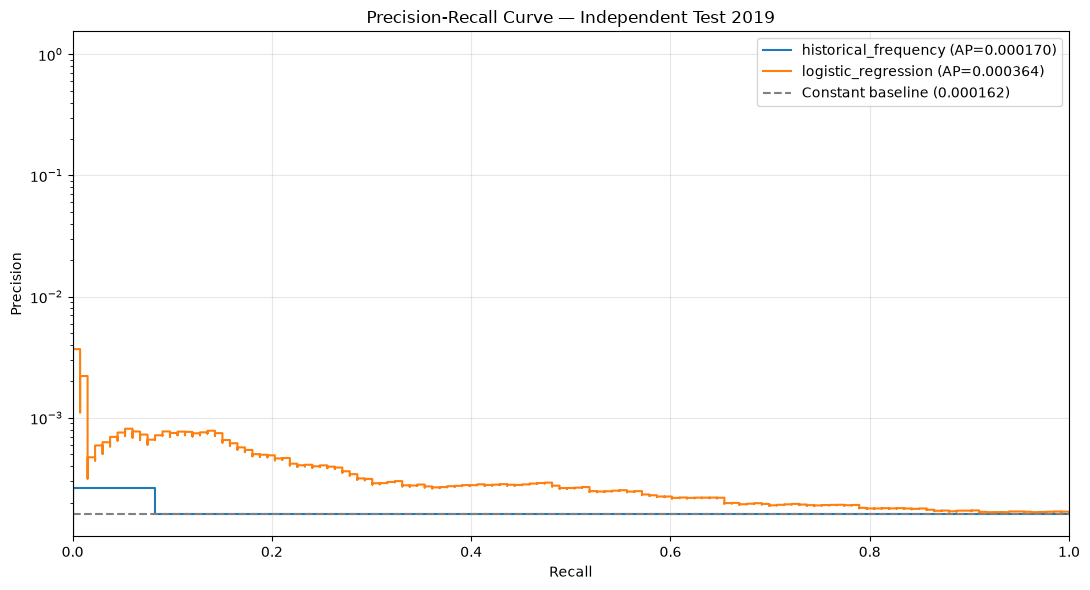

In [32]:
plt.figure(figsize=(11, 6))

for name, scores in final_scores.items():
    if name == "constant_score":
        continue

    precision, recall, _ = precision_recall_curve(
        y_final_test,
        scores
    )

    ap = average_precision_score(
        y_final_test,
        scores
    )

    plt.step(
        recall,
        precision,
        where="post",
        label=f"{name} (AP={ap:.6f})"
    )

plt.axhline(
    y=y_final_test.mean(),
    linestyle="--",
    color="gray",
    label=f"Constant baseline ({y_final_test.mean():.6f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Independent Test 2019")

plt.xlim(0, 1)
plt.yscale("log")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
error_df = final_test_df[[
    "intersection_id",
    "prediction_date",
    "target_date",
    "target",
    "traffic_missing"
]].copy()

error_df["risk_score"] = final_scores[FINAL_MODEL_NAME]

for fraction in [0.05, 0.10]:
    label = int(fraction * 100)

    error_df[f"selected_at_{label}pct"] = (
        top_k_predictions(
            error_df["risk_score"],
            fraction
        )
    )

print("Error analysis dataset:", error_df.shape)

Error analysis dataset: (819654, 8)


In [34]:
season_mapping = {
    12: "winter",
    1: "winter",
    2: "winter",
    3: "spring",
    4: "spring",
    5: "spring",
    6: "summer",
    7: "summer",
    8: "summer",
    9: "autumn",
    10: "autumn",
    11: "autumn"
}

error_df["season"] = (
    error_df["target_date"]
    .dt.month
    .map(season_mapping)
)

error_df["traffic_group"] = (
    error_df["traffic_missing"]
    .map({
        0: "available",
        1: "missing"
    })
)

history_events = pd.read_csv(
    DATA_DIR / "ksi_matched_events.csv",
    parse_dates=["event_date"]
)

history_cutoff = pd.Timestamp("2019-01-01")

historical_counts = (
    history_events.loc[
        history_events["event_date"] < history_cutoff
    ]
    .drop_duplicates([
        "intersection_id",
        "collision_id",
        "event_date"
    ])
    .groupby("intersection_id")
    .size()
)

error_df["pretest_ksi_count"] = (
    error_df["intersection_id"]
    .map(historical_counts)
    .fillna(0)
    .astype(int)
)

error_df["history_group"] = pd.cut(
    error_df["pretest_ksi_count"],
    bins=[-1, 0, 2, np.inf],
    labels=[
        "no_history",
        "1-2_events",
        "3plus_events"
    ]
)

print("Error analysis groups created.")

Error analysis groups created.


In [35]:
def evaluate_slice(frame):
    n = len(frame)
    positives = int(frame["target"].sum())

    metrics = {
        "observations": n,
        "positives": positives,
        "prevalence": positives / n,
        "average_precision": np.nan,
        "ap_lift": np.nan,
        "roc_auc": np.nan
    }

    if positives > 0:
        ap = average_precision_score(
            frame["target"],
            frame["risk_score"]
        )

        metrics["average_precision"] = ap
        metrics["ap_lift"] = ap / metrics["prevalence"]

    if 0 < positives < n:
        metrics["roc_auc"] = roc_auc_score(
            frame["target"],
            frame["risk_score"]
        )

    for label in [5, 10]:
        selected = frame[f"selected_at_{label}pct"]

        tp = int((frame["target"] * selected).sum())

        selected_count = int(selected.sum())

        fp = selected_count - tp
        fn = positives - tp

        metrics[f"selected_{label}pct"] = selected_count

        metrics[f"selection_rate_{label}pct"] = (
            selected_count / n
        )

        metrics[f"captured_{label}pct"] = tp
        metrics[f"false_positives_{label}pct"] = fp
        metrics[f"false_negatives_{label}pct"] = fn

        metrics[f"recall_{label}pct"] = (
            tp / positives if positives > 0 else np.nan
        )

        metrics[f"precision_{label}pct"] = (
            tp / selected_count
            if selected_count > 0 else np.nan
        )

    return metrics

In [36]:
slice_results = []

slice_columns = [
    "season",
    "history_group",
    "traffic_group"
]

for slice_column in slice_columns:
    for group_name, group_df in error_df.groupby(
        slice_column,
        observed=True
    ):
        metrics = evaluate_slice(group_df)

        slice_results.append({
            "slice_type": slice_column,
            "slice_name": str(group_name),
            **metrics
        })

error_analysis_df = pd.DataFrame(slice_results)

for slice_column in slice_columns:
    print(f"\n{slice_column.upper()}")

    display(
        error_analysis_df.loc[
            error_analysis_df["slice_type"] == slice_column,
            [
                "slice_name",
                "observations",
                "positives",
                "average_precision",
                "ap_lift",
                "roc_auc",
                "selection_rate_5pct",
                "recall_5pct",
                "precision_5pct",
                "captured_5pct",
                "selection_rate_10pct",
                "recall_10pct",
                "precision_10pct",
                "captured_10pct",
                "false_negatives_10pct"
            ]
        ].round(8)
    )


SEASON


,slice_name,observations,positives,average_precision,ap_lift,roc_auc,selection_rate_5pct,recall_5pct,precision_5pct,captured_5pct,selection_rate_10pct,recall_10pct,precision_10pct,captured_10pct,false_negatives_10pct
0,autumn,205478,31,0.001020,6.759456,0.689095,0.065623,0.354839,0.000816,11,0.131148,0.451613,0.000520,14,17
1,spring,207736,29,0.000213,1.525133,0.581706,0.038852,0.068966,0.000248,2,0.077781,0.103448,0.000186,3,26
2,summer,207736,45,0.000389,1.793554,0.607661,0.063475,0.177778,0.000607,8,0.127850,0.244444,0.000414,11,34
3,winter,198704,28,0.000280,1.985454,0.574314,0.031414,0.071429,0.000320,2,0.061906,0.142857,0.000325,4,24



HISTORY_GROUP


,slice_name,observations,positives,average_precision,ap_lift,roc_auc,selection_rate_5pct,recall_5pct,precision_5pct,captured_5pct,selection_rate_10pct,recall_10pct,precision_10pct,captured_10pct,false_negatives_10pct
4,no_history,529254,65,0.000447,3.640089,0.598996,0.005806,0.046154,0.000976,3,0.027469,0.107692,0.000481,7,58
5,1-2_events,253374,54,0.000321,1.505369,0.553692,0.084172,0.203704,0.000516,11,0.180125,0.296296,0.000351,16,38
6,3plus_events,37026,14,0.001023,2.704483,0.633207,0.447874,0.642857,0.000543,9,0.588478,0.642857,0.000413,9,5



TRAFFIC_GROUP


,slice_name,observations,positives,average_precision,ap_lift,roc_auc,selection_rate_5pct,recall_5pct,precision_5pct,captured_5pct,selection_rate_10pct,recall_10pct,precision_10pct,captured_10pct,false_negatives_10pct
7,available,495858,96,0.000436,2.250121,0.624835,0.082651,0.239583,0.000561,23,0.165301,0.333333,0.00039,32,64
8,missing,323796,37,0.000163,1.428612,0.541000,0.000000,0.000000,NaN,0,0.000000,0.000000,NaN,0,37


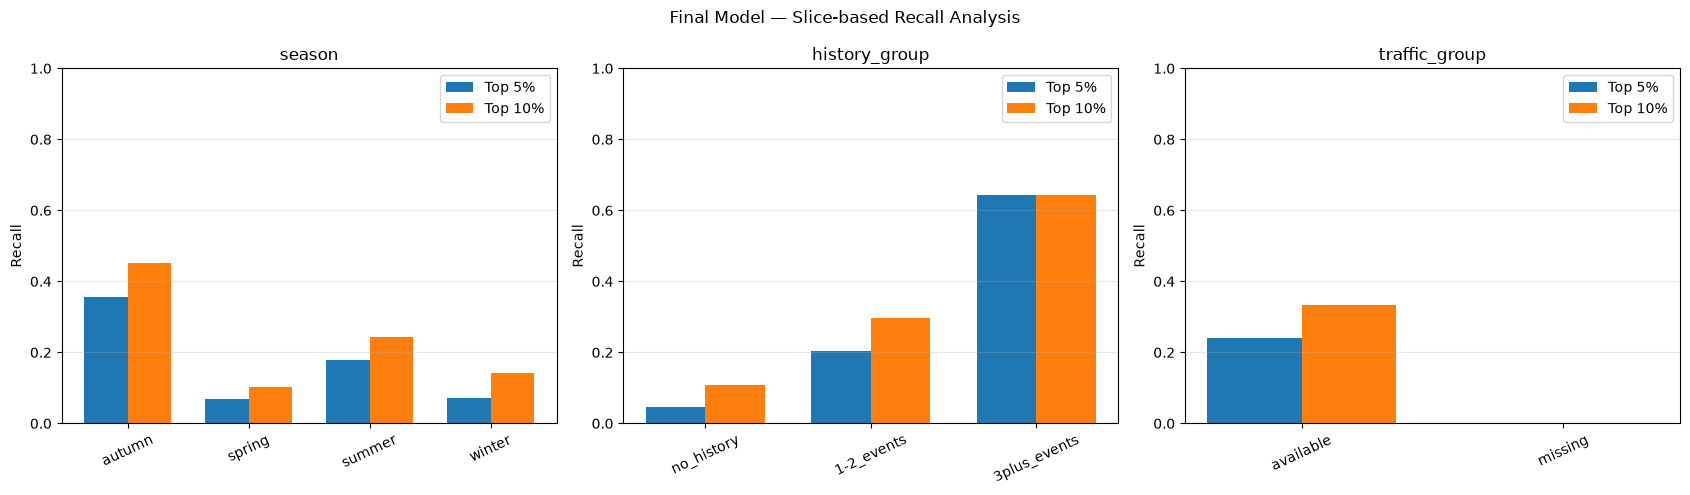

In [37]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for ax, slice_column in zip(
    axes,
    slice_columns
):
    plot_df = error_analysis_df.loc[
        error_analysis_df["slice_type"] == slice_column
    ]

    positions = np.arange(len(plot_df))

    ax.bar(
        positions - 0.18,
        plot_df["recall_5pct"],
        width=0.36,
        label="Top 5%"
    )

    ax.bar(
        positions + 0.18,
        plot_df["recall_10pct"],
        width=0.36,
        label="Top 10%"
    )

    ax.set_xticks(positions)

    ax.set_xticklabels(
        plot_df["slice_name"],
        rotation=25
    )

    ax.set_title(slice_column)
    ax.set_ylabel("Recall")
    ax.set_ylim(0, 1)

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Final Model — Slice-based Recall Analysis"
)

plt.tight_layout()
plt.show()

In [38]:
for slice_column in slice_columns:
    group_results = error_analysis_df.loc[
        error_analysis_df["slice_type"] == slice_column
    ]

    assert group_results["observations"].sum() == len(error_df)

    assert (
        group_results["positives"].sum()
        == error_df["target"].sum()
    )

    for label in [5, 10]:
        selected = error_df[f"selected_at_{label}pct"]

        assert (
            group_results[f"selected_{label}pct"].sum()
            == selected.sum()
        )

        assert (
            group_results[f"captured_{label}pct"].sum()
            == (error_df["target"] * selected).sum()
        )

print("All error analysis consistency checks passed.")

All error analysis consistency checks passed.


In [39]:
report_tables = {
    "outer_fold_metrics": outer_results_df,
    "outer_cv_summary": outer_summary,
    "development_metrics": dev_results_df,
    "model_comparison": model_comparison,
    "final_test_metrics": final_test_results_df,
    "generalization_comparison": (
        generalization_comparison
        .rename_axis("metric")
        .reset_index()
    ),
    "error_analysis": error_analysis_df
}

for name, frame in report_tables.items():
    export_frame = frame.copy()

    if "best_params" in export_frame.columns:
        export_frame["best_params"] = (
            export_frame["best_params"]
            .map(json.dumps)
        )

    output_path = W14_REPORTS_DIR / f"{name}.csv"

    export_frame.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {name}.csv")

Saved: outer_fold_metrics.csv
Saved: outer_cv_summary.csv
Saved: development_metrics.csv
Saved: model_comparison.csv
Saved: final_test_metrics.csv
Saved: generalization_comparison.csv
Saved: error_analysis.csv


In [40]:
selected_test = (
    final_test_results_df
    .set_index("model")
    .loc[FINAL_MODEL_NAME]
)

traffic_missing_slice = (
    error_analysis_df.loc[
        (error_analysis_df["slice_type"] == "traffic_group")
        & (error_analysis_df["slice_name"] == "missing")
    ].iloc[0]
)

evaluation_summary = {
    "week": "W14",
    "model": FINAL_MODEL_NAME,
    "parameters": FINAL_MODEL_PARAMS,

    "training": {
        "observations": len(X_final_train),
        "positives": int(y_final_train.sum()),
        "fit_seconds": float(final_fit_seconds)
    },

    "test": {
        "start": str(FINAL_TEST_START.date()),
        "end": str(FINAL_TEST_END.date()),
        "observations": len(X_final_test),
        "positives": int(y_final_test.sum()),
        "prevalence": float(y_final_test.mean()),
        "predict_seconds": float(final_predict_seconds)
    },

    "metrics": {
        "average_precision": float(
            selected_test["average_precision"]
        ),
        "ap_lift": float(selected_test["ap_lift"]),
        "pr_auc_trapezoidal": float(
            selected_test["pr_auc"]
        ),
        "roc_auc": float(selected_test["roc_auc"]),
        "recall_at_5pct": float(
            selected_test["recall_at_5pct"]
        ),
        "recall_at_10pct": float(
            selected_test["recall_at_10pct"]
        ),
        "precision_at_5pct": float(
            selected_test["precision_at_5pct"]
        ),
        "precision_at_10pct": float(
            selected_test["precision_at_10pct"]
        ),
        "captured_at_5pct": int(
            selected_test["captured_at_5pct"]
        ),
        "captured_at_10pct": int(
            selected_test["captured_at_10pct"]
        )
    },

    "diagnostic_findings": {
        "missing_traffic_observations": int(
            traffic_missing_slice["observations"]
        ),
        "missing_traffic_positives": int(
            traffic_missing_slice["positives"]
        ),
        "missing_traffic_recall_at_10pct": float(
            traffic_missing_slice["recall_10pct"]
        )
    },

    "limitations": [
        "Extremely low absolute precision",
        "High variability across temporal folds",
        "Uneven performance across seasonal groups",
        "No missing-traffic observations selected at Top 5% or Top 10%",
        "Historical reporting latency not verified",
        "Fixed intersection cohort",
        "Global ranking is not equivalent to daily operational ranking",
        "Probability calibration not validated",
        "Not suitable for automated safety-critical decisions"
    ]
}

summary_path = (
    W14_REPORTS_DIR / "evaluation_summary.json"
)

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(
        evaluation_summary,
        file,
        indent=4,
        allow_nan=False
    )

print(f"Saved: {summary_path}")

Saved: ..\reports\evaluation_w14\evaluation_summary.json


In [41]:
FIGURES_DIR = W14_REPORTS_DIR / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    FIGURES_DIR / "error_analysis.png",
    dpi=200,
    bbox_inches="tight"
)

pr_fig, ax = plt.subplots(figsize=(11, 6))

for name, scores in final_scores.items():
    if name == "constant_score":
        continue

    precision, recall, _ = precision_recall_curve(
        y_final_test,
        scores
    )

    ap = average_precision_score(
        y_final_test,
        scores
    )

    ax.step(
        recall,
        precision,
        where="post",
        label=f"{name} (AP={ap:.6f})"
    )

ax.axhline(
    y=y_final_test.mean(),
    linestyle="--",
    color="gray",
    label="Constant baseline"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve — Independent Test 2019")

ax.set_xlim(0, 1)
ax.set_yscale("log")

ax.legend()
ax.grid(alpha=0.3)

pr_fig.tight_layout()

pr_fig.savefig(
    FIGURES_DIR / "final_test_pr_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.close(pr_fig)

print("Evaluation figures saved.")

Evaluation figures saved.
